In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [2]:
class CustomRandomForest:
    def __init__(self, n_estimators=100, max_features='sqrt', max_depth=None, min_samples_split=2):
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.trees = []
        
    def _bootstrap_sample(self, X, y):
        """Create a bootstrap sample of the data"""
        n_samples = X.shape[0]
        idxs = np.random.choice(n_samples, n_samples, replace=True)
        return X[idxs], y[idxs]
    
    def _get_feature_subset(self, n_features):
        """Get a random subset of features"""
        if self.max_features == 'sqrt':
            max_feats = int(np.sqrt(n_features))
        elif self.max_features == 'log2':
            max_feats = int(np.log2(n_features))
        elif isinstance(self.max_features, float):
            max_feats = int(self.max_features * n_features)
        elif isinstance(self.max_features, int):
            max_feats = self.max_features
        else:
            max_feats = n_features
        
        return np.random.choice(n_features, max_feats, replace=False)
    
    def custom_train(self, X, y, X_val=None, y_val=None, early_stopping_rounds=10):
        n_features = X.shape[1]
        self.trees = []
        
        # For early stopping
        best_val_score = float('inf')
        no_improve_count = 0
        best_n_trees = 0
        
        for i in range(self.n_estimators):
            # Create a bootstrap sample
            X_boot, y_boot = self._bootstrap_sample(X, y)
            
            # Select feature subset for this tree
            feature_idxs = self._get_feature_subset(n_features)
            
            # Instead of using RandomForestRegressor with n_estimators=1, 
            # we can use a single DecisionTreeRegressor
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split
            )
            
            tree.fit(X_boot[:, feature_idxs], y_boot)
            self.trees.append((tree, feature_idxs))
            
            # Early stopping check with validation data
            if X_val is not None and y_val is not None:
                val_pred = self.predict(X_val)
                val_score = mean_squared_error(y_val, val_pred)
                
                print(f"Tree {i+1}/{self.n_estimators}, Validation MSE: {val_score:.4f}")
                
                if val_score < best_val_score:
                    best_val_score = val_score
                    no_improve_count = 0
                    best_n_trees = i + 1
                else:
                    no_improve_count += 1
                    
                if no_improve_count >= early_stopping_rounds:
                    print(f"Early stopping at {i+1} trees. Best was {best_n_trees} trees with MSE: {best_val_score:.4f}")
                    # Keep only the best trees
                    self.trees = self.trees[:best_n_trees]
                    break
    
    def predict(self, X):
        """Make predictions with the forest"""
        predictions = np.zeros(X.shape[0])
        
        for tree, feature_idxs in self.trees:
            predictions += tree.predict(X[:, feature_idxs]).flatten()
            
        return predictions / len(self.trees)

In [7]:
class MultiStepForecaster:
    def __init__(self, n_steps=16):
        self.n_steps = n_steps
        self.models = []
        
    def prepare_multistep_data(self, data, feature_cols, target_col):
        """Prepare data for multi-step prediction"""
        X_list = []
        y_list = []
        
        # For each step ahead, create a model
        for step in range(1, self.n_steps + 1):
            # Shift the target to create the future value to predict
            shifted_target = data[target_col].shift(-step)
            
            # Remove rows with NaN (at the end after shifting)
            step_data = data[feature_cols].copy()
            step_data['target'] = shifted_target
            step_data = step_data.dropna()
            
            X_step = step_data[feature_cols].values
            y_step = step_data['target'].values
            
            X_list.append(X_step)
            y_list.append(y_step)
            
        return X_list, y_list
    
    def train(self, X_list, y_list, max_depth=10, n_estimators=30, early_stopping_rounds=5):
        """Train a separate model for each prediction step"""
        self.models = []
        
        for step, (X_step, y_step) in enumerate(zip(X_list, y_list)):
            print(f"Training model for step {step+1}/{self.n_steps}")
            
            # Split into train and validation
            X_train, X_val, y_train, y_val = train_test_split(X_step, y_step, test_size=0.2, random_state=42)
            
            # Create and train model for this step
            model = CustomRandomForest(n_estimators=n_estimators, max_depth=max_depth)
            model.custom_train(X_train, y_train, X_val, y_val, early_stopping_rounds=early_stopping_rounds)
            
            self.models.append(model)
            
    def predict(self, X):
        """Make predictions for all future steps"""
        predictions = np.zeros((X.shape[0], self.n_steps))
        
        for step, model in enumerate(self.models):
            predictions[:, step] = model.predict(X)
            
        return predictions

In [8]:
print("Loading data...")
# Load the datasets
train_data = pd.read_csv('dataset/train_dataset.csv')
test_features = pd.read_csv('dataset/test_features.csv')

print("Preprocessing data...")
# Convert date to datetime format and extract time-based features
train_data['date'] = pd.to_datetime(train_data['date'])
train_data['hour'] = train_data['date'].dt.hour
train_data['day_of_week'] = train_data['date'].dt.dayofweek
train_data['month'] = train_data['date'].dt.month

test_features['date'] = pd.to_datetime(test_features['date'])
test_features['hour'] = test_features['date'].dt.hour
test_features['day_of_week'] = test_features['date'].dt.dayofweek
test_features['month'] = test_features['date'].dt.month

Loading data...
Preprocessing data...


In [9]:
feature_columns = [
    'temperature_exterieure', 'humidite', 'ensoleillement', 'vitesse_vent',
    'direction_vent', 'temperature_interieure',
    'hour', 'day_of_week', 'month'
]

print("Setting up multi-step forecasting...")
# Setup multi-step forecasting
forecaster = MultiStepForecaster(n_steps=16)

# Prepare data for multi-step forecasting
X_list, y_list = forecaster.prepare_multistep_data(
    train_data, 
    feature_cols=feature_columns, 
    target_col='puissance_cvac'
)

Setting up multi-step forecasting...


In [10]:
print("Training models...")
# Train the multi-step forecaster (this will train a model for each step)
forecaster.train(X_list, y_list, max_depth=8, n_estimators=30, early_stopping_rounds=3)

Training models...
Training model for step 1/16
Tree 1/30, Validation MSE: 0.3388
Tree 2/30, Validation MSE: 0.5899
Tree 3/30, Validation MSE: 0.3824
Tree 4/30, Validation MSE: 0.3060
Tree 5/30, Validation MSE: 0.4010
Tree 6/30, Validation MSE: 0.4289
Tree 7/30, Validation MSE: 0.5737
Early stopping at 7 trees. Best was 4 trees with MSE: 0.3060
Training model for step 2/16
Tree 1/30, Validation MSE: 1.4513
Tree 2/30, Validation MSE: 1.0473
Tree 3/30, Validation MSE: 1.3167
Tree 4/30, Validation MSE: 1.1891
Tree 5/30, Validation MSE: 1.3230
Early stopping at 5 trees. Best was 2 trees with MSE: 1.0473
Training model for step 3/16
Tree 1/30, Validation MSE: 1.0776
Tree 2/30, Validation MSE: 0.4303
Tree 3/30, Validation MSE: 0.7706
Tree 4/30, Validation MSE: 0.5357
Tree 5/30, Validation MSE: 0.3872
Tree 6/30, Validation MSE: 0.3275
Tree 7/30, Validation MSE: 0.2924
Tree 8/30, Validation MSE: 0.3377
Tree 9/30, Validation MSE: 0.4413
Tree 10/30, Validation MSE: 0.3971
Early stopping at 10 tr

In [11]:
print("Making predictions...")
# Prepare test data
test_X = test_features[feature_columns].values

# Make predictions for the next 16 time steps
test_predictions = forecaster.predict(test_X)

Making predictions...


Predictions saved to predictions.csv
Sample prediction plot saved to sample_prediction.png


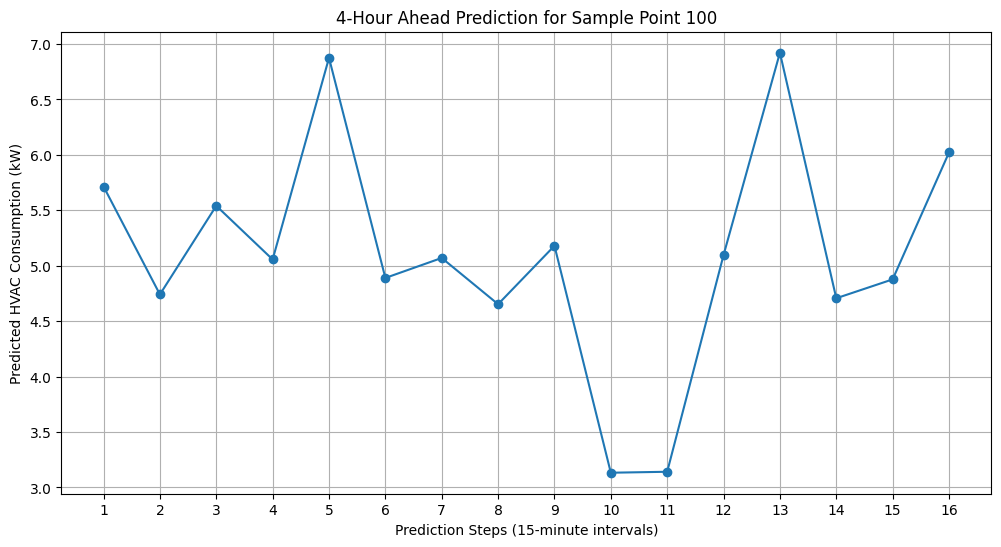

In [12]:
prediction_df = pd.DataFrame({
    'ID': test_features['ID'],
    'date': test_features['date']
})

# Add each step's prediction to the dataframe
for i in range(16):
    prediction_df[f'step_{i+1}'] = test_predictions[:, i]

# Save predictions to CSV
prediction_df.to_csv('predictions.csv', index=False)
print("Predictions saved to predictions.csv")

# Plot predictions for a sample point
sample_idx = 100  # Choose a sample data point
plt.figure(figsize=(12, 6))
plt.plot(range(1, 17), test_predictions[sample_idx], marker='o')
plt.xlabel('Prediction Steps (15-minute intervals)')
plt.ylabel('Predicted HVAC Consumption (kW)')
plt.title(f'4-Hour Ahead Prediction for Sample Point {sample_idx}')
plt.grid(True)
plt.xticks(range(1, 17))
plt.savefig('sample_prediction.png')
print("Sample prediction plot saved to sample_prediction.png")

In [14]:
from sklearn.metrics import mean_squared_error
import numpy as np

print("Evaluating RMSE on validation sets...")
val_rmse_per_step = []

for step, (X_step, y_step) in enumerate(zip(X_list, y_list)):
    # Same split used during training
    _, X_val, _, y_val = train_test_split(X_step, y_step, test_size=0.2, random_state=42)

    # Predict with the trained model
    model = forecaster.models[step]
    y_pred = model.predict(X_val)

    # Compute RMSE for this step
    rmse = mean_squared_error(y_val, y_pred)
    val_rmse_per_step.append(rmse)

# Print results
for i, rmse in enumerate(val_rmse_per_step):
    print(f"Step {i+1}: RMSE = {rmse:.4f}")

Evaluating RMSE on validation sets...
Step 1: RMSE = 0.3060
Step 2: RMSE = 1.0473
Step 3: RMSE = 0.2924
Step 4: RMSE = 0.5460
Step 5: RMSE = 0.4191
Step 6: RMSE = 0.3385
Step 7: RMSE = 0.3731
Step 8: RMSE = 0.6399
Step 9: RMSE = 1.3552
Step 10: RMSE = 1.1629
Step 11: RMSE = 1.2423
Step 12: RMSE = 0.5231
Step 13: RMSE = 0.3060
Step 14: RMSE = 0.8967
Step 15: RMSE = 0.5577
Step 16: RMSE = 0.5726
